# 01 · Datos: origen, integridad y partición temporal

**Responsabilidad:** cargar el dataset crudo, verificar que es exactamente el archivo del experimento y mostrar cómo se corta en tramos.

- **Fuente:** Kaggle, *microsoft-stock-price-analysis-and-forecasting* (Ashraf Khetran), licencia CC BY 4.0. Archivo `data/raw/MSFT_5years_cleaned.csv`.
- **Precios ajustados por dividendos.** Validado contra Yahoo Finance en `reports/validacion_datos.md`.
- **Regla:** el archivo crudo nunca se edita. Su huella SHA-256 está fijada en `config/experiment.toml`.

In [1]:
import os, pathlib, warnings
warnings.filterwarnings("ignore")
root = pathlib.Path.cwd()
while not (root / "pyproject.toml").exists():
    root = root.parent
os.chdir(root)  # todas las rutas del proyecto son relativas a la raíz

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from msft_mlops.config import load_config
from msft_mlops.data import load_raw
from msft_mlops.features import build_dataset

pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.figsize": (10, 4), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "lines.linewidth": 2})
# Paleta validada (dataviz): A azul, B naranja, C aqua; baselines y neutros en gris.
COLOR = {"A": "#2a78d6", "B": "#eb6834", "C": "#1baf7a"}
MARKER = {"A": "o", "B": "s", "C": "^"}
GRIS = "#8a8a85"

cfg = load_config()
f = cfg["features"]
FEAT_KW = dict(n_lags=f["n_lags"], ma_windows=tuple(f["ma_windows"]), vol_ma_window=f["vol_ma_window"])
raw = load_raw(cfg)              # falla si el SHA-256 no coincide con config/experiment.toml
ds = build_dataset(raw, **FEAT_KW)
FEATS = [c for c in ds.columns if c != "y"]
print(f"raw: {len(raw)} filas | dataset modelable: {len(ds)} filas, {len(FEATS)} features")

raw: 1254 filas | dataset modelable: 1234 filas, 9 features


## 1. Integridad del archivo

La huella SHA-256 es como una "huella digital" del archivo: si cambia un solo byte, cambia por completo. Si no coincide con la de la configuración, el pipeline se detiene.

In [2]:
from msft_mlops.data import sha256_file, validate_integrity
print("SHA-256 archivo :", sha256_file(cfg.data_path))
print("SHA-256 config  :", cfg.data_sha256)
print("Avisos de integridad:", validate_integrity(raw) or "ninguno")
raw.head()

SHA-256 archivo : 1617484d95f94f5968c176246decee0680c39cdb7733b503d73bda03eafe86f7
SHA-256 config  : 1617484d95f94f5968c176246decee0680c39cdb7733b503d73bda03eafe86f7
Avisos de integridad: ninguno


,date,close,high,low,open,volume,price_change,price_change_pct,day_of_week,month,year,quarter
0,2021-02-04,232.218,233.398,230.645,232.842,25296100,NaN,NaN,3,2,2021,1
1,2021-02-05,232.401,233.437,230.693,232.429,18054800,0.182,0.079,4,2,2021,1
2,2021-02-08,232.660,233.821,231.067,233.312,22211900,0.259,0.111,0,2,2021,1
3,2021-02-09,233.907,234.857,231.614,232.084,23565000,1.247,0.536,1,2,2021,1
4,2021-02-10,232.995,235.970,231.144,235.087,22186700,-0.912,-0.390,2,2,2021,1


## 2. La serie completa

Rango: 2021-02-04 → 2026-02-02 (1254 días bursátiles)


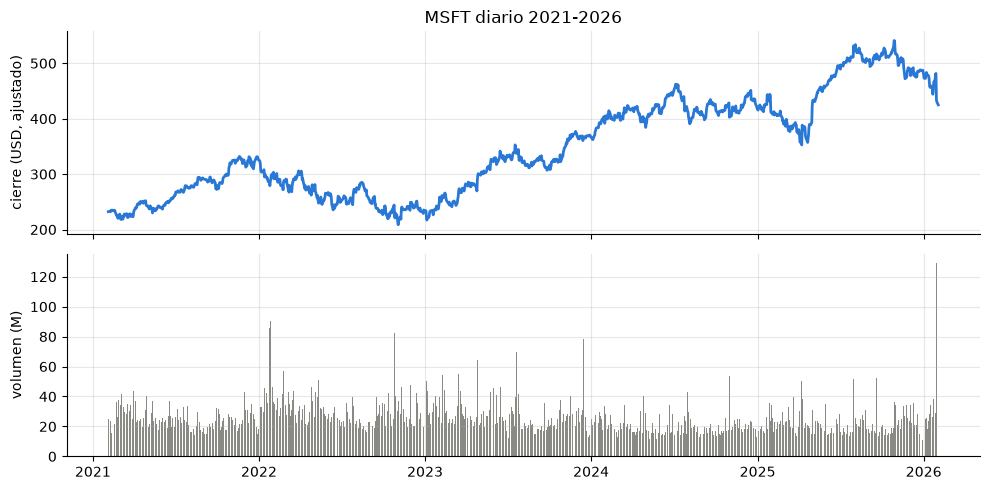

In [3]:
print(f"Rango: {raw.date.min().date()} → {raw.date.max().date()} ({len(raw)} días bursátiles)")
fig, (a1, a2) = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
a1.plot(raw.date, raw.close, color=COLOR["A"]); a1.set_ylabel("cierre (USD, ajustado)")
a2.bar(raw.date, raw.volume / 1e6, color=GRIS, width=1); a2.set_ylabel("volumen (M)")
a1.set_title("MSFT diario 2021-2026"); plt.tight_layout()

**Cómo leerlo:** arriba el precio de cierre y abajo el volumen negociado por día.

**Qué concluimos:** Se ven regímenes muy distintos: caída en 2022, recuperación fuerte en 2023–2024 y máximos en 2025. Un modelo entrenado con un régimen puede fallar en otro, y esa es justamente la **deriva** que el experimento estudia. El precio se duplica en el periodo; por eso las features deben ser relativas (notebook 02).

## 3. Partición temporal (sin barajar)

No se usa validación cruzada K-fold porque mezclaría pasado y futuro (literatura [15], [18], [19], decisión D1).

| Tramo | Uso |
|---|---|
| descarte inicial | primeros 19 días: sin historia suficiente para la media móvil de 20 días |
| ajuste (fit) | entrenar cada combinación de hiperparámetros |
| validación | calificar cada combinación con datos no vistos y elegir la mejor |
| inicial = ajuste + validación | entrenar el modelo de partida, el mismo para A, B y C |
| 8 ventanas semestrales | **prueba**: aquí se miden y comparan los grupos |
| excluido | semestre incompleto (enero 2026) y la última fila, que no tiene día siguiente |

,tramo,desde,hasta,filas
0,descarte inicial,2021-02-04,2021-03-03,19
1,ajuste (fit),2021-03-04,2021-09-30,147
2,validación,2021-10-01,2021-12-31,64
3,prueba 2022-H1,2022-01-03,2022-06-30,124
4,prueba 2022-H2,2022-07-01,2022-12-30,127
5,prueba 2023-H1,2023-01-03,2023-06-30,124
6,prueba 2023-H2,2023-07-03,2023-12-29,126
7,prueba 2024-H1,2024-01-02,2024-06-28,124
8,prueba 2024-H2,2024-07-01,2024-12-31,128
9,prueba 2025-H1,2025-01-02,2025-06-30,122


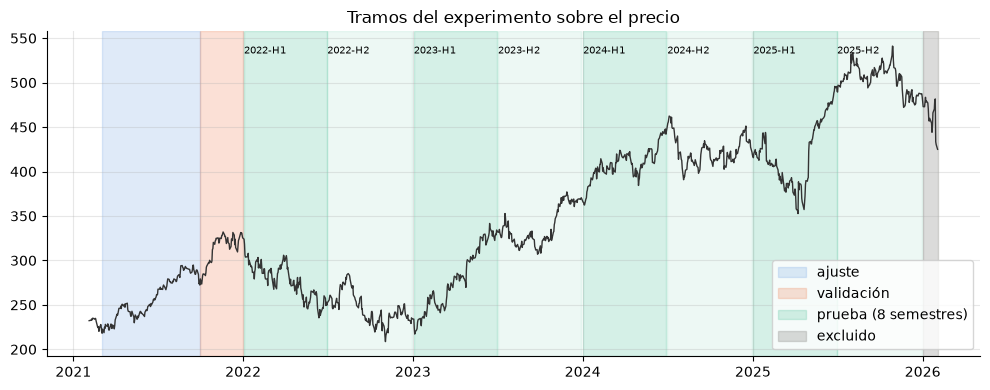

In [4]:
from msft_mlops.windows import split_2021, test_windows, excluded_tail
fit_df, val_df, initial_df = split_2021(ds, cfg["split"])
windows = test_windows(ds, cfg["split"])
tail = excluded_tail(ds, cfg["split"])
filas = [("descarte inicial", raw.date.iloc[0], ds.index[0] - pd.Timedelta(days=1), (raw.date < ds.index[0]).sum()),
         ("ajuste (fit)", fit_df.index[0], fit_df.index[-1], len(fit_df)),
         ("validación", val_df.index[0], val_df.index[-1], len(val_df))]
filas += [(f"prueba {w.window_id}", w.start, w.end, w.n) for w in windows]
filas += [("excluido (semestre incompleto)", tail.index[0], tail.index[-1], len(tail)),
          ("última fila (sin etiqueta)", raw.date.iloc[-1], raw.date.iloc[-1], 1)]
tramos = pd.DataFrame(filas, columns=["tramo", "desde", "hasta", "filas"])
tramos["desde"] = pd.to_datetime(tramos.desde).dt.date; tramos["hasta"] = pd.to_datetime(tramos.hasta).dt.date
assert tramos.filas.sum() == len(raw), "la partición debe cubrir todas las filas"

fig, ax = plt.subplots()
ax.plot(raw.date, raw.close, color="#333", lw=1)
ax.axvspan(fit_df.index[0], fit_df.index[-1], color=COLOR["A"], alpha=0.15, label="ajuste")
ax.axvspan(val_df.index[0], val_df.index[-1], color=COLOR["B"], alpha=0.2, label="validación")
for i, w in enumerate(windows):
    ax.axvspan(w.start, w.end, color=COLOR["C"], alpha=0.08 if i % 2 else 0.18, label="prueba (8 semestres)" if i == 0 else None)
    ax.text(w.start, raw.close.max(), w.window_id, fontsize=7, va="top")
ax.axvspan(tail.index[0], raw.date.iloc[-1], color=GRIS, alpha=0.3, label="excluido")
ax.legend(loc="lower right"); ax.set_title("Tramos del experimento sobre el precio"); plt.tight_layout()
tramos

**Cómo leerlo:** cada franja de color es un tramo; la tabla da sus fechas exactas y el número de filas.

**Qué concluimos:** Los tramos suman exactamente las 1254 filas (lo verifica el `assert`): no se pierde ningún dato sin explicación. El modelo inicial aprende con 211 días de 2021 y se pone a prueba con 1003 días que nunca vio.

## 4. Tasa de subidas por tramo

`y = 1` si el cierre de mañana supera al de hoy. La proporción de subidas `p` es un **conteo real** sobre los precios, no un modelo, y solo se conoce cuando el tramo termina. Describe el régimen del mercado y fija el F1 del baseline "siempre sube": `2p/(1+p)`.

,tramo,p_subida,F1 siempre_sube = 2p/(1+p)
0,2021,0.521,0.685
1,2022-H1,0.484,0.652
2,2022-H2,0.441,0.612
3,2023-H1,0.516,0.681
4,2023-H2,0.587,0.740
5,2024-H1,0.540,0.702
6,2024-H2,0.531,0.694
7,2025-H1,0.566,0.723
8,2025-H2,0.516,0.680


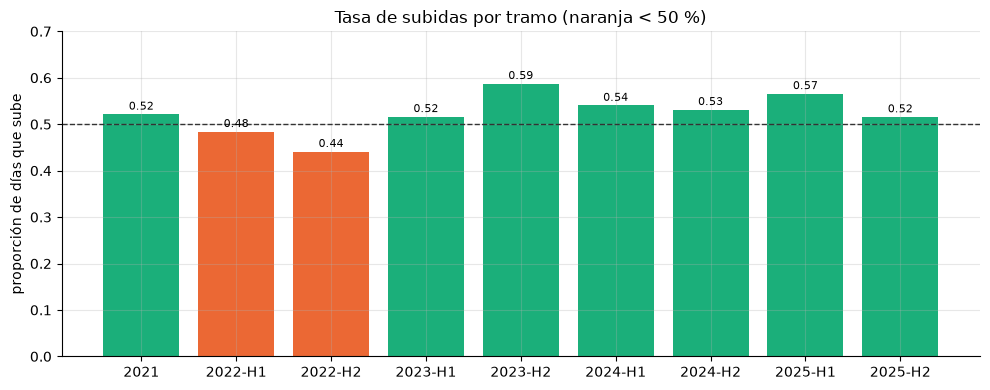

In [5]:
tasa = pd.DataFrame({"tramo": ["2021"] + [w.window_id for w in windows],
                     "p_subida": [initial_df.y.mean()] + [w.data.y.mean() for w in windows]})
tasa["F1 siempre_sube = 2p/(1+p)"] = 2 * tasa.p_subida / (1 + tasa.p_subida)
fig, ax = plt.subplots()
cols = [COLOR["B"] if p < 0.5 else COLOR["C"] for p in tasa.p_subida]
ax.bar(tasa.tramo, tasa.p_subida, color=cols); ax.axhline(0.5, color="#333", ls="--", lw=1)
for x, p in zip(tasa.tramo, tasa.p_subida): ax.text(x, p + 0.01, f"{p:.2f}", ha="center", fontsize=8)
ax.set_ylim(0, 0.7); ax.set_ylabel("proporción de días que sube"); ax.set_title("Tasa de subidas por tramo (naranja < 50 %)")
plt.tight_layout(); tasa

**Cómo leerlo:** cada barra es la proporción de días que la acción subió; la línea punteada marca 50 %.

**Qué concluimos:** 2022 fue bajista (subió menos de la mitad de los días) y 2023-H2 fue el más alcista (59 %). Este vaivén explica buena parte de los resultados: los modelos reentrenados **copian** la tasa de subidas del año con que se entrenaron (notebook 06).